In [1]:
import pandas as pd
import numpy as np
from datetime import date
import matplotlib.pyplot as plt

In [2]:
def conversion_a_datetime(str_col):
    try:
        # ISO8061: %Y-%m-%d %H:%M
        dt_col = pd.to_datetime(str_col, format="ISO8601")
    except ValueError:
        # Archivos encontrados con formato no ISO8601:
        # Año 2023 mes 11
        # Año 2024 mes 09
        # Año 2024 mes 10
        dt_col = pd.to_datetime(str_col, format="%d/%m/%Y %H:%M")
    
    return dt_col

In [3]:
def leer_datos_mensuales(direccion, convencion, ano, mes):
    data_file_name = f"{convencion}_{ano}_{mes:02}.csv"
    filepath = f"{direccion}/{data_file_name}"

    # Leer archivos ya sea con utf-8 o latin-1 en caso de error
    try:
        df = pd.read_csv(filepath, encoding="utf-8")
    except UnicodeDecodeError:
        df = pd.read_csv(filepath, encoding="latin-1")
    
    # Archivo de año 2023, mes 04 encontrado con nombre incorrecto
    if "A}äe_nacimiento" in df:
        df = df.rename(columns={"A}äe_nacimiento": "Año_de_nacimiento"})

    # Por auditoría, guardar el nombre del archivo
    df["Archivo_de_origen"] = filepath
    
    # Convertir inicio y fin de viaje a datetime
    df["Inicio_del_viaje"] = conversion_a_datetime(df["Inicio_del_viaje"])
    df["Fin_del_viaje"] = conversion_a_datetime(df["Fin_del_viaje"])
        
    return df

In [ ]:
def leer_datos_anuales(direccion, convencion, ano):
    # Obtener mes máximo a consultar (12 para años anteriores, mes actual - 1 para año actual)
    today = date.today()
    mes_max = today.month - 1 if int(ano) == today.year else 12

    # Inicializar dataframe de salida con la primera lectura de archivo
    resultado = leer_datos_mensuales(direccion, convencion, ano, 1)

    if mes_max == 1:
        return resultado
    else:
        # Concatenar los otros archivos del año en un solo dataframe
        for mes in range(2, mes_max+1):
            # Se leen los archivos para cada mes
            df_a_concatenar = leer_datos_mensuales(direccion, convencion, ano, mes)

            # Se revisa si el esquema del archivo leido es igual al de los ya leidos
            try:
                pd.testing.assert_series_equal(resultado.dtypes, df_a_concatenar.dtypes)
            except AssertionError:
                print(f"Diferencia en esquema encontrada entre archivos:")
                print(f"{convencion}_{ano}_{mes:02}.csv")
                print(f"{convencion}_{ano}_{(mes-1):02}.csv")
                raise

            # Se concatena el dataframe del archivo leido al dataframe de salida
            resultado = pd.concat([resultado, df_a_concatenar])
            
    # Se resetea el índice del dataframe de salida
    resultado = resultado.reset_index(drop=True)
    
    return resultado


In [5]:
def leer_multiples_datos_anuales(direccion, convencion, ano_min, ano_max):

    resultado = leer_datos_anuales(direccion, convencion, ano_min)

    if ano_min == ano_max:
        return resultado
    else:
        for ano in range(ano_min, ano_max+1):
            df_a_concatenar = leer_datos_anuales(direccion, convencion, ano)
            
            try:
                pd.testing.assert_series_equal(resultado.dtypes, df_a_concatenar.dtypes)
            except AssertionError:
                print(f"Diferencia en esquema encontrada entre años {ano-1} y {ano}")
                raise
            
            resultado = pd.concat([resultado, df_a_concatenar])
        
    resultado = resultado.reset_index(drop=True)
    
    return resultado

In [ ]:
direccion = "../data/raw"
convencion="datos_abiertos"

# Se lee todo del 2020 a 2026 (NOTA: archivos guardados localmente de forma manual)
df = leer_multiples_datos_anuales(direccion, convencion, 2020, 2026)

In [7]:
def redondear_a_primer_dia_del_mes(dt_col):
    col_redondeado = dt_col.astype(str).str.slice(stop=8) + "01"
    return pd.to_datetime(col_redondeado)

In [8]:
df["Mes_redondeado"] = redondear_a_primer_dia_del_mes(df["Inicio_del_viaje"])

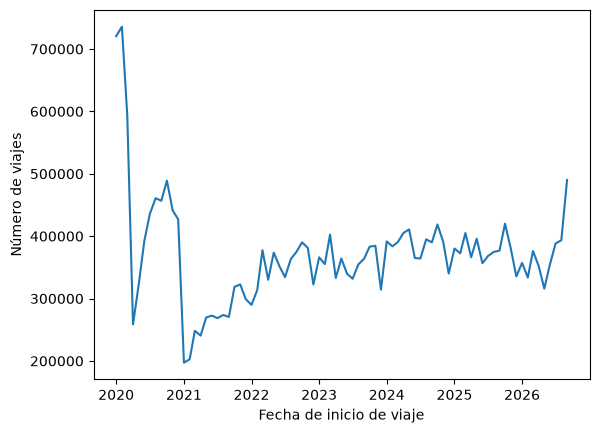

In [9]:
groupedby = df.groupby(df["Mes_redondeado"])['Viaje_Id'].count()

plt.plot(groupedby.index, groupedby)
plt.xlabel("Fecha de inicio de viaje")
plt.ylabel("Número de viajes")
plt.show()

In [ ]:
# Solo Genero y Año de nacimiento tienen nulls
# Pendiente revisar si hay strings actuando como nulos
df.isna().sum()

Viaje_Id                  0
Usuario_Id                0
Genero               141907
Año_de_nacimiento     38453
Inicio_del_viaje          0
Fin_del_viaje             0
Origen_Id                 0
Destino_Id                0
Archivo_de_origen         0
Mes_redondeado            0
dtype: int64

In [ ]:
# No hay correlacion entre los nulos de Genero y los nulos de año de nacimiento
null_matrix = df[["Genero","Año_de_nacimiento"]].isnull().astype(int)
null_corr = null_matrix.corr(method='pearson')
null_corr

,Genero,Año_de_nacimiento
Genero,1.000000,0.099051
Año_de_nacimiento,0.099051,1.000000


In [ ]:
# 29779602 records no tienen ninguna de estas columnas (Genero, Año de nacimiento) nulas
# 165406 tienen una u otra nula
# 7477 tienen ambas nulas
null_matrix.sum(axis=1).value_counts()

0    29779602
1      165406
2        7477
Name: count, dtype: int64

In [43]:
columns_with_variance = null_matrix.loc[:, null_matrix.var() > 0].columns

In [ ]:
# Los ids no se deben analizar como numéricos (absurdamente ineficiente, no hacer esto en prod)
# Solo es para usar bien los describe() por ahora
id_cols = ["Viaje_Id", "Usuario_Id", "Origen_Id", "Destino_Id"]
df[id_cols] = df[id_cols].astype(str)

In [27]:
cat_cols = df.select_dtypes(include=["str","object"]).columns.tolist()
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
time_cols = df.select_dtypes(include=["datetime"]).columns.tolist()
assert len(cat_cols) + len(num_cols) + len(time_cols) == len(df.columns)

In [ ]:
cat_stats_df = df[cat_cols].describe().T
cat_stats_df

# El archivo 2020_02 (justo antes del inicio de la pandemia) es el que tiene más records (del 2020 en adelante)
# No todos los viajes son únicos, algunos Ids se duplican
# 72% de los registros son de hombres

,count,unique,top,freq
Viaje_Id,29952485,27085655,14420217,2
Usuario_Id,29952485,81245,51332,19077
Genero,29810578,2,M,21752114
Origen_Id,29952485,475,51,620864
Destino_Id,29952485,475,51,792575
Archivo_de_origen,29952485,81,../data/raw/datos_abiertos_2020_02.csv,735728


In [33]:
df["Genero"].value_counts()*100/len(df)

Genero
M    72.622068
F    26.904158
Name: count, dtype: float64

In [ ]:
# Qué ocurre cuando Genero es nulo?
df[df["Genero"].isnull()].head(100)

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,Archivo_de_origen,Mes_redondeado
230,14420499,634722,NaN,NaN,2020-01-01 10:00:48,2020-01-01 10:16:46,77,36,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
334,14420610,634711,NaN,NaN,2020-01-01 10:49:31,2020-01-01 11:05:36,28,56,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
335,14420611,634711,NaN,NaN,2020-01-01 10:49:37,2020-01-01 11:05:24,28,56,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
368,14420644,634725,NaN,NaN,2020-01-01 10:59:51,2020-01-01 11:14:58,198,50,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
378,14420654,634722,NaN,NaN,2020-01-01 11:04:27,2020-01-01 11:25:08,36,34,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
...,...,...,...,...,...,...,...,...,...,...
26890,14453499,635541,NaN,NaN,2020-01-05 10:30:26,2020-01-05 10:43:53,133,221,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
26891,14453500,635541,NaN,NaN,2020-01-05 10:30:30,2020-01-05 10:44:45,133,221,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
26901,14453510,635544,NaN,NaN,2020-01-05 10:31:38,2020-01-05 10:45:57,196,50,../data/raw/datos_abiertos_2020_01.csv,2020-01-01
26916,14453525,635552,NaN,NaN,2020-01-05 10:33:33,2020-01-05 12:19:07,194,194,../data/raw/datos_abiertos_2020_01.csv,2020-01-01


In [30]:
num_stats_df = df[num_cols].describe().T
num_stats_df["kurt"] = df[num_cols].kurt()
num_stats_df["skew"] = df[num_cols].skew()
num_stats_df

# Año de nacimiento mínimo de 1 está muy raro
# Año de nacimiento máximo de 2023 también

,count,mean,std,min,25%,50%,75%,max,kurt,skew
Año_de_nacimiento,29914032.0,1988.843542,16.415916,1.0,1983.0,1992.0,1997.0,2023.0,7750.860874,-66.510731


In [ ]:
# Todos parecen ser del 2023 en adelante, no parecen están correctos
df[(df["Año_de_nacimiento"] == 2023)].Inicio_del_viaje.dt.year.value_counts()

Inicio_del_viaje
2024    596
2025    398
2023    157
Name: count, dtype: int64

<Axes: >

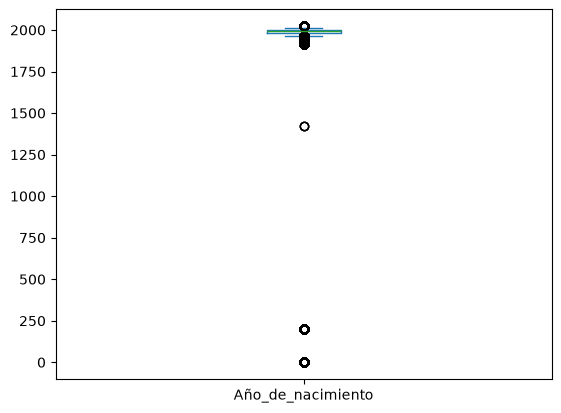

In [ ]:
# Ademas de un año de nacimiento 1, hay ~200, ~1400
# Hay que quitarlos
df[num_cols].plot.box()